# SC2001 Project 2 
## The Dijkstra’s Algorithm Part(c)


In [34]:
import time
import random
import math
import heapq
import matplotlib.pyplot as plt

To compare both approaches fairly, both algorithms must execute on the exact same graph topology, edge connections, and edge weights

In [42]:
def generate_unified_graph(num_v, density=None, target_edges=None, weight_range=(1, 100)):
    matrix = [[0] * num_v for _ in range(num_v)]
    adj_list = [[] for _ in range(num_v)]
    edges_set = set()
    num_e = 0

    def add_edge(u, v):
        nonlocal num_e
        if u != v and (u, v) not in edges_set:
            w = random.randint(*weight_range)
            matrix[u][v] = w
            adj_list[u].append((v, w))
            edges_set.add((u, v))
            num_e += 1

    # 1. Connect every vertex to guarantee reachability from source 0
    for node in range(1, num_v):
        parent = random.randrange(node)
        add_edge(parent, node)

    # 2. Add remaining edges to match the desired count or density
    if target_edges is not None:
        needed_edges = target_edges
    elif density is not None:
        needed_edges = int(num_v * (num_v - 1) * density)
    else:
        needed_edges = num_v * 3

    while num_e < needed_edges and num_e < num_v * (num_v - 1):
        u = random.randrange(num_v)
        v = random.randrange(num_v)
        add_edge(u, v)

    return matrix, adj_list, num_e

Integrates the exact algorithm structures from Part (a) and Part (b) so both compute the single-source shortest path from source = 0

In [36]:
# Part (a): Adjacency Matrix + Array Priority Queue (O(|V|^2))
class ArrayPriorityQueue:
    def __init__(self, vertices, distances):
        self.queue = []
        for v in vertices:
            self.queue.append([v, distances[v]])
    
    def isEmpty(self):
        return len(self.queue) == 0
    
    def getMin(self):
        if self.isEmpty():
            return None
        minIndex = 0
        for i in range(1, len(self.queue)):
            if self.queue[i][1] < self.queue[minIndex][1]:
                minIndex = i
        return self.queue.pop(minIndex)
    
    def updatePriority(self, vertex, newPriority):
        for v in self.queue:
            if v[0] == vertex:
                v[1] = newPriority
                return

def dijkstra_part_a(graph, source=0):
    numV = len(graph)
    dist = [float('inf')] * numV
    dist[source] = 0

    vertices = list(range(numV))
    queue = ArrayPriorityQueue(vertices, dist)

    while not queue.isEmpty():
        res = queue.getMin()
        if res is None:
            break
        u, current_distance = res
        if current_distance == float('inf'):
            break

        for v in range(numV):
            if graph[u][v] > 0:
                new_distance = dist[u] + graph[u][v]
                if new_distance < dist[v]:
                    dist[v] = new_distance
                    queue.updatePriority(v, new_distance)
    return dist


# Part (b): Adjacency List + Min-Heap (O((|V| + |E|) log |V|))

def dijkstra_part_b(adj_list, source=0):
    numV = len(adj_list)
    dist = [float('inf')] * numV
    dist[source] = 0

    # Priority queue stores tuples of (distance, vertex)
    pq = [(0, source)]

    while pq:
        d_u, u = heapq.heappop(pq)

        # Skip outdated/stale entries
        if d_u > dist[u]:
            continue

        for v, weight in adj_list[u]:
            if dist[u] + weight < dist[v]:
                dist[v] = dist[u] + weight
                heapq.heappush(pq, (dist[v], v))
    return dist

In [37]:
def benchmark(matrix, adj_list, repeats=5):
    times_a = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        dijkstra_part_a(matrix, source=0)
        times_a.append(time.perf_counter() - t0)

    # Part (b)
    times_b = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        dijkstra_part_b(adj_list, source=0)
        times_b.append(time.perf_counter() - t0)

    return sum(times_a) / repeats, sum(times_b) / repeats

### Experiment 1: Comparison on Sparse Graphs ($|E| \approx 3|V|$)
In sparse networks (e.g., road routing, communication networks), $|E| = O(|V|)$. 
Here, Part (b)'s $O(|V| \log |V|)$ should theoretically outperform Part (a)'s $O(|V|^2)$.

=== Running Experiment 1: Sparse Graphs (|E| ≈ 3|V|) ===
|V| =  100 | |E| =   300 | Part (a) [Matrix+Array]: 0.000700s | Part (b) [List+Heap]: 0.000107s
|V| =  200 | |E| =   600 | Part (a) [Matrix+Array]: 0.002183s | Part (b) [List+Heap]: 0.000155s
|V| =  300 | |E| =   900 | Part (a) [Matrix+Array]: 0.005595s | Part (b) [List+Heap]: 0.000187s
|V| =  400 | |E| =  1200 | Part (a) [Matrix+Array]: 0.009331s | Part (b) [List+Heap]: 0.000285s
|V| =  500 | |E| =  1500 | Part (a) [Matrix+Array]: 0.014210s | Part (b) [List+Heap]: 0.000336s
|V| =  600 | |E| =  1800 | Part (a) [Matrix+Array]: 0.020374s | Part (b) [List+Heap]: 0.000417s
|V| =  700 | |E| =  2100 | Part (a) [Matrix+Array]: 0.028721s | Part (b) [List+Heap]: 0.000525s
|V| =  800 | |E| =  2400 | Part (a) [Matrix+Array]: 0.037445s | Part (b) [List+Heap]: 0.000562s


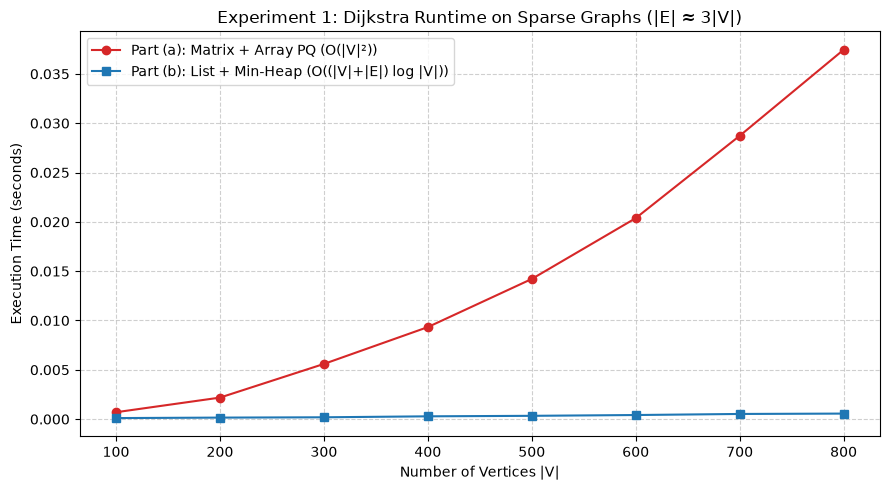

In [43]:
v_sizes_sparse = [100, 200, 300, 400, 500, 600, 700, 800]
sparse_times_a = []
sparse_times_b = []

print("=== Running Experiment 1: Sparse Graphs (|E| ≈ 3|V|) ===")
for v in v_sizes_sparse:
    # Target exactly 3*V edges, connected
    matrix, adj_list, e = generate_unified_graph(v, target_edges=3 * v)
    
    ta, tb = benchmark(matrix, adj_list, repeats=3)
    sparse_times_a.append(ta)
    sparse_times_b.append(tb)
    print(f"|V| = {v:4d} | |E| = {e:5d} | Part (a) [Matrix+Array]: {ta:.6f}s | Part (b) [List+Heap]: {tb:.6f}s")

# Plotting Experiment 1
plt.figure(figsize=(9, 5))
plt.plot(v_sizes_sparse, sparse_times_a, 'o-', color='tab:red', label="Part (a): Matrix + Array PQ (O(|V|²))")
plt.plot(v_sizes_sparse, sparse_times_b, 's-', color='tab:blue', label="Part (b): List + Min-Heap (O((|V|+|E|) log |V|))")
plt.xlabel("Number of Vertices |V|")
plt.ylabel("Execution Time (seconds)")
plt.title("Experiment 1: Dijkstra Runtime on Sparse Graphs (|E| ≈ 3|V|)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Experiment 2: Comparison on Dense Graphs ($d = 0.8$, $|E| = O(|V|^2)$)
In dense graphs, $|E| \approx |V|^2$. Part (b) becomes $O(|V|^2 \log |V|)$ due to frequent heap operations, while Part (a) remains $O(|V|^2)$.


=== Running Experiment 2: Dense Graphs (Density = 0.8) ===
|V| =  100 | |E| =   7920 | Part (a) [Matrix+Array]: 0.001189s | Part (b) [List+Heap]: 0.000578s
|V| =  200 | |E| =  31840 | Part (a) [Matrix+Array]: 0.004988s | Part (b) [List+Heap]: 0.001620s
|V| =  300 | |E| =  71760 | Part (a) [Matrix+Array]: 0.010737s | Part (b) [List+Heap]: 0.007449s
|V| =  400 | |E| = 127680 | Part (a) [Matrix+Array]: 0.019701s | Part (b) [List+Heap]: 0.015988s
|V| =  500 | |E| = 199600 | Part (a) [Matrix+Array]: 0.032699s | Part (b) [List+Heap]: 0.032183s
|V| =  600 | |E| = 287520 | Part (a) [Matrix+Array]: 0.047636s | Part (b) [List+Heap]: 0.051371s
|V| =  700 | |E| = 391440 | Part (a) [Matrix+Array]: 0.066519s | Part (b) [List+Heap]: 0.074150s
|V| =  800 | |E| = 511360 | Part (a) [Matrix+Array]: 0.087519s | Part (b) [List+Heap]: 0.100631s


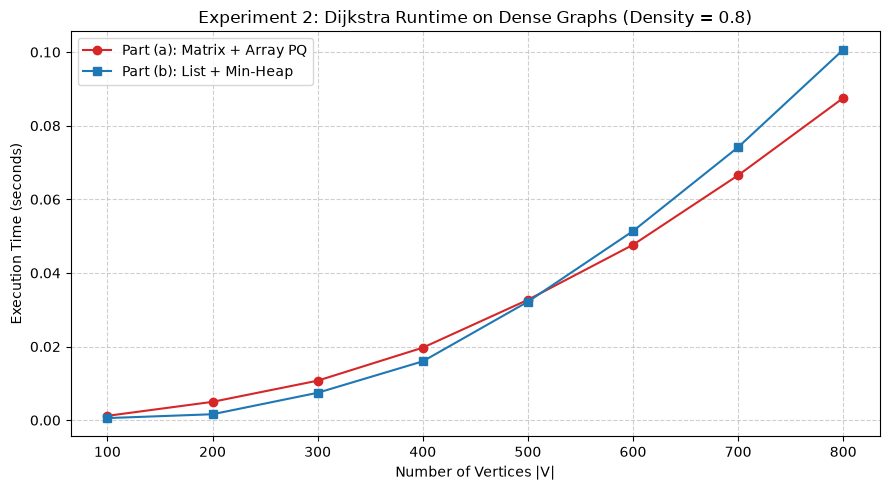

In [44]:
v_sizes_dense = [100, 200, 300, 400, 500, 600, 700, 800]
dense_times_a = []
dense_times_b = []

print("\n=== Running Experiment 2: Dense Graphs (Density = 0.8) ===")
for v in v_sizes_dense:
    matrix, adj_list, e = generate_unified_graph(v, density=0.8)
    
    ta, tb = benchmark(matrix, adj_list, repeats=3)
    dense_times_a.append(ta)
    dense_times_b.append(tb)
    print(f"|V| = {v:4d} | |E| = {e:6d} | Part (a) [Matrix+Array]: {ta:.6f}s | Part (b) [List+Heap]: {tb:.6f}s")

# Plotting Experiment 2
plt.figure(figsize=(9, 5))
plt.plot(v_sizes_dense, dense_times_a, 'o-', color='tab:red', label="Part (a): Matrix + Array PQ")
plt.plot(v_sizes_dense, dense_times_b, 's-', color='tab:blue', label="Part (b): List + Min-Heap")
plt.xlabel("Number of Vertices |V|")
plt.ylabel("Execution Time (seconds)")
plt.title("Experiment 2: Dijkstra Runtime on Dense Graphs (Density = 0.8)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Experiment 3: Effect of Edge Density with Fixed $|V| = 500$
By fixing $|V|$, we isolate the effect of increasing edge count $|E|$ on both implementations.


=== Running Experiment 3: Varying Edge Density (Fixed |V| = 500) ===
Density = 0.05 | |E| =  12475 | Part (a): 0.018290s | Part (b): 0.001581s
Density = 0.10 | |E| =  24950 | Part (a): 0.020501s | Part (b): 0.003980s
Density = 0.20 | |E| =  49900 | Part (a): 0.026418s | Part (b): 0.007715s
Density = 0.30 | |E| =  74850 | Part (a): 0.024527s | Part (b): 0.008438s
Density = 0.40 | |E| =  99800 | Part (a): 0.027425s | Part (b): 0.015330s
Density = 0.50 | |E| = 124750 | Part (a): 0.028607s | Part (b): 0.018909s
Density = 0.60 | |E| = 149700 | Part (a): 0.028941s | Part (b): 0.023504s
Density = 0.70 | |E| = 174650 | Part (a): 0.033552s | Part (b): 0.029003s
Density = 0.80 | |E| = 199600 | Part (a): 0.032451s | Part (b): 0.033326s
Density = 0.90 | |E| = 224550 | Part (a): 0.033372s | Part (b): 0.038430s


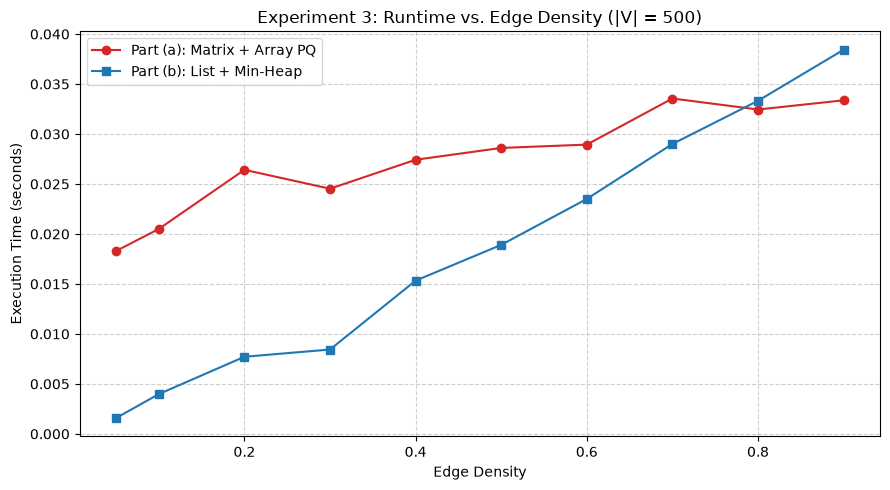

In [46]:
fixed_v = 500
densities = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
density_times_a = []
density_times_b = []

print(f"\n=== Running Experiment 3: Varying Edge Density (Fixed |V| = {fixed_v}) ===")
for d in densities:
    matrix, adj_list, e = generate_unified_graph(fixed_v, density=d)
    
    ta, tb = benchmark(matrix, adj_list, repeats=3)
    density_times_a.append(ta)
    density_times_b.append(tb)
    print(f"Density = {d:.2f} | |E| = {e:6d} | Part (a): {ta:.6f}s | Part (b): {tb:.6f}s")

# Plotting Experiment 3
plt.figure(figsize=(9, 5))
plt.plot(densities, density_times_a, 'o-', color='tab:red', label="Part (a): Matrix + Array PQ")
plt.plot(densities, density_times_b, 's-', color='tab:blue', label="Part (b): List + Min-Heap")
plt.xlabel("Edge Density")
plt.ylabel("Execution Time (seconds)")
plt.title(f"Experiment 3: Runtime vs. Edge Density (|V| = {fixed_v})")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Part (c): Compare the two implementations in (a) and (b). Discuss which implementation is better and in what circumstances.

#### 1. Summary Comparison Table

| Metric / Scenario | Part (a): Matrix + Array PQ | Part (b): List + Min-Heap | Winner | Explanation |
| :--- | :--- | :--- | :--- | :--- |
| **Time Complexity** | $\Theta(V^2)$ | $O((V + E) \log V)$ | **Depends on density** | Part (a) depends only on $V$; Part (b) depends on both $V$ and $E$. |
| **Space Complexity** | $\Theta(V^2)$ | $\Theta(V + E)$ | **Part (b)** | Adjacency list requires far less memory when edges are sparse. |
| **Sparse Graph ($E \approx 3V$)** | Slower ($\approx 0.037\text{ s}$) | **Much faster ($\approx 0.0005\text{ s}$)** | **Part (b) wins** | Part (b) only relaxes existing edges; Part (a) scans every cell in each matrix row. |
| **Dense Graph ($d = 0.8$)** | **Faster ($\approx 0.087\text{ s}$)** | Slower ($\approx 0.100\text{ s}$) | **Part (a) wins** | Part (b) incurs heavy $\log V$ min-heap insertion overhead; Part (a) has no tree balancing. |
| **Varying Density (Fixed $V = 500$)** | Stays relatively flat | Increases with edge count | **Part (a) is stable** | Part (a) loops over all $V^2$ matrix cells regardless of edge count. |

---

#### 2. Key Insights & Crossover Points

1. **Sparse Graphs:** Part (b) runs in $O(V \log V)$ versus Part (a)'s $O(V^2)$. In our experiment, Part (b) is over **$70\times$ faster** at $V = 800$.
2. **Dense Graphs:** When $E \to V^2$, Part (b) degrades to $O(V^2 \log V)$. An empirical crossover occurs around **$V \approx 500$**, beyond which Part (a) becomes faster due to simple array indexing and better CPU cache locality.
3. **Density Impact:** At fixed $V = 500$, Part (b) runtime grows linearly with edge density and crosses over to become slower than Part (a) around **density $\approx 0.85$**.

---

#### 3. When to Use Which?

* **Use Part (b) (Adjacency List + Min-Heap):**
  - When the graph is **sparse** ($E \ll V^2$), such as road networks, web graphs, or social networks.
  - When memory is limited, as an adjacency list avoids allocating a massive $V \times V$ array.

* **Use Part (a) (Adjacency Matrix + Array):**
  - When the graph is **dense or fully connected** ($E \approx V^2$), such as all-pairs distance metrics or airline route matrices.
  - When $V$ is relatively small, where direct memory lookups beat pointer-chasing and heap overhead.